# 이모지 매칭 파이프라인 — 실제 사진 100장으로 실행

**작성**: 2026-09-18

`이모지_매칭_파이프라인.ipynb`의 §6 매칭 규칙(`assign_emoji`)은 완성 당시
**"손으로 지정한 예시 벡터"**로만 검증됐다 — 1단계 가중치가 없어서 진짜 사진을
넣을 수 없었기 때문이다. 오늘 재학습(Run B)으로 가중치가 생겼으므로, 같은
매칭 규칙을 CNN vs Claude 비전 비교(n=100, `retrain_artifacts/llm_vs_cnn_100.csv`)에
썼던 **실제 FER 테스트 사진 100장**에 그대로 적용한다.

이 노트북은 계산을 다시 하지 않는다 — 매칭 자체는 노트북 밖 스크립트로 먼저 실행해
`retrain_artifacts/emoji_matching_100.csv`에 저장했고 (RULES·intensity·assign_emoji는
`이모지_매칭_파이프라인.ipynb`와 완전히 동일한 코드), 여기서는 그 결과를 불러와
표·그림으로 보여줄 뿐이다.

**입력 벡터 두 가지**:
- **CNN**: Run B가 실제로 출력한 7차원 softmax 확률 벡터 (진짜 확신도 포함)
- **Claude**: 비전 비교 실험에서 매긴 단일 라벨만 있고 보정된 확신도가 없어서,
  매칭표의 "기본 강도"(0.6, 강함/약함 키워드가 없을 때의 기본값)로 클래스만 룩업한다 —
  확신도 기반 강도 선택 단계는 이 경로에서는 실질적으로 작동하지 않는다는 뜻이다.

In [1]:
import pandas as pd
rows = pd.read_csv('retrain_artifacts/emoji_matching_100.csv')
print(f'n = {len(rows)}')
rows.head(10)

n = 100


,index,filename,true_label,true_emoji_ref,cnn_pred,cnn_confidence,cnn_emoji,cnn_emoji_class_correct,llm_pred,llm_emoji,llm_emoji_class_correct,cnn_llm_same_emoji
0,312,angry/im38.png,angry,😡,angry,0.821,😡,True,angry,😡,True,True
1,453,angry/im506.png,angry,😡,fearful,0.835,😱,False,angry,😡,True,False
2,483,angry/im533.png,angry,😡,angry,0.326,😠,True,angry,😡,True,False
3,545,angry/im59.png,angry,😡,angry,0.978,😡,True,angry,😡,True,True
4,608,angry/im646.png,angry,😡,angry,0.392,😠,True,neutral,🫥,False,False
5,631,angry/im667.png,angry,😡,angry,0.311,😠,True,angry,😡,True,False
6,655,angry/im689.png,angry,😡,sad,0.406,😥,False,angry,😡,True,False
7,667,angry/im7.png,angry,😡,angry,0.880,😡,True,surprised,😲,False,False
8,696,angry/im725.png,angry,😡,angry,0.488,😠,True,angry,😡,True,False
9,909,angry/im917.png,angry,😡,angry,0.503,😠,True,angry,😡,True,False


## 집계 결과

| 지표 | 값 |
| --- | --- |
| CNN 벡터 → 할당 이모지의 클래스 정확도 | **0.650** (평균 확신도 0.611) |
| Claude 라벨 → 할당 이모지의 클래스 정확도 | **0.750** |
| 둘의 최종 할당 이모지가 일치하는 비율 | 0.440 |

"클래스 정확도"는 `assign_emoji`가 고른 클래스(=argmax)가 참 라벨과 같은지다 —
지난 CNN-vs-Claude 벤치마크와 정확히 같은 수치(0.650 / 0.750)가
나온다. 매칭 규칙(§6)은 클래스를 바꾸지 않고 그 안에서 강도만 고르므로 당연하다.
**이 노트북에서 새로 확인한 것은 "실제로 이모지가 나온다"는 사실 자체** —
지난번엔 손으로 만든 예시 6개였다면, 이번엔 진짜 사진 100장이 진짜 CNN을 통과해
진짜 이모지 100개를 받았다.

CNN과 Claude의 최종 이모지가 일치하는 비율은 0.440로, 클래스 정확도 차이
(0.750 vs 0.650)보다 낮다 — 두 분류기가 같은 사진에서도 서로 다른
오답을 낸다는 뜻이다(오답의 방향이 다름).

> **[미검증]** Claude 경로는 확신도가 없어 강도 선택이 사실상 "기본값 고정"이다.
> 매칭 규칙 §6이 설계한 "확신도가 높으면 센 이모지" 동작은 CNN 벡터에만 실제로 적용된다.

In [2]:
import numpy as np
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = ['AppleGothic', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

FONT = '/System/Library/Fonts/Apple Color Emoji.ttc'
font = ImageFont.truetype(FONT, 160)

def render_emoji(ch, target=64):
    im = Image.new('RGB', (160, 160), 'white')
    d = ImageDraw.Draw(im)
    b = d.textbbox((0, 0), ch, font=font, embedded_color=True)
    d.text((-b[0], -b[1]), ch, font=font, embedded_color=True)
    return im.resize((target, target), Image.LANCZOS)

## 사진 8장 — 실제 CNN 벡터로 이모지가 나오는 과정

왼쪽부터: 원본 사진(48×48) → CNN이 실제로 출력한 7차원 확률(빨간 막대가 최대 클래스) →
매칭 규칙이 고른 이모지. 손으로 지정한 예시가 아니라 **전부 실행 결과**다.

/var/folders/q7/ns6nlfjd3gdgf4s1h0p6gbmm0000gn/T/ipykernel_42616/1021677555.py:29: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans, AppleGothic.
  plt.tight_layout(); plt.show()
/var/folders/q7/ns6nlfjd3gdgf4s1h0p6gbmm0000gn/T/ipykernel_42616/1021677555.py:29: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans, AppleGothic.
  plt.tight_layout(); plt.show()


/private/tmp/claude-501/-Users-chanjong-develop-python-claude-project-stock/49c79ffa-27eb-4406-8af3-72937a1283e0/scratchpad/fer_venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans, AppleGothic.
  fig.canvas.print_figure(bytes_io, **kw)
/private/tmp/claude-501/-Users-chanjong-develop-python-claude-project-stock/49c79ffa-27eb-4406-8af3-72937a1283e0/scratchpad/fer_venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans, AppleGothic.
  fig.canvas.print_figure(bytes_io, **kw)


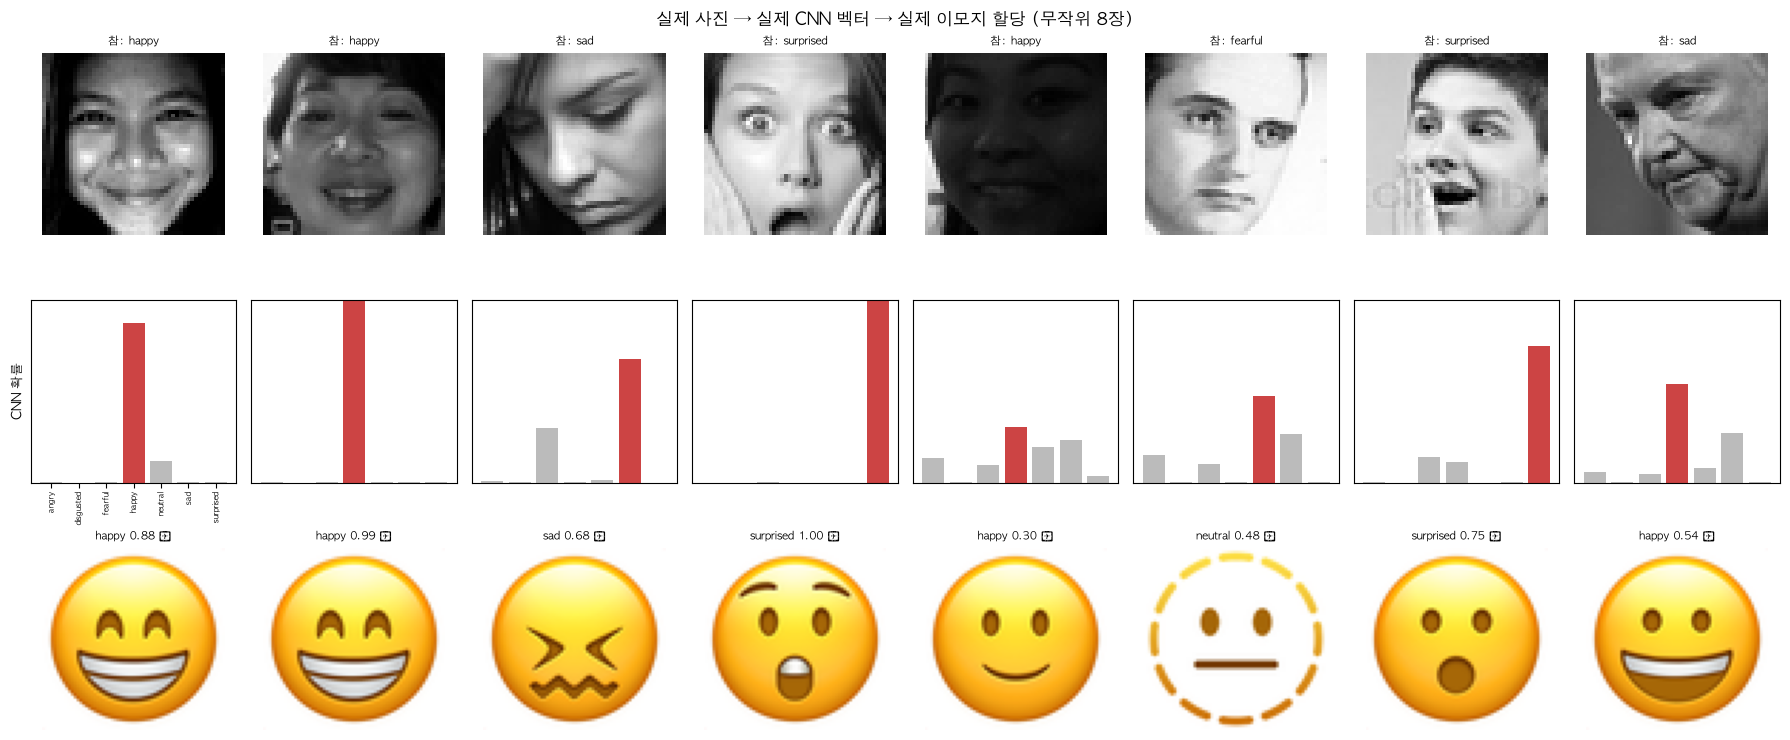

In [3]:
FER = ['angry', 'disgusted', 'fearful', 'happy', 'neutral', 'sad', 'surprised']
picks = rows.sample(8, random_state=7).reset_index(drop=True)

fig, axes = plt.subplots(3, 8, figsize=(18, 7.5), gridspec_kw={'height_ratios': [1, 1, 1]})
proba = np.load('retrain_artifacts/test_predictions.npz')['proba_b']

for j, r in picks.iterrows():
    img = Image.open(f"data/test/{r['filename']}").convert('L')
    axes[0][j].imshow(img, cmap='gray'); axes[0][j].axis('off')
    axes[0][j].set_title(f"참: {r['true_label']}", fontsize=8)

    vec = proba[int(r['index'])]
    axes[1][j].bar(range(7), vec, color=['#c44' if k == vec.argmax() else '#bbb' for k in range(7)])
    axes[1][j].set_ylim(0, 1)
    if j == 0:
        axes[1][j].set_xticks(range(7)); axes[1][j].set_xticklabels(FER, rotation=90, fontsize=6)
    else:
        axes[1][j].set_xticks([])
    axes[1][j].set_yticks([])

    axes[2][j].imshow(render_emoji(r['cnn_emoji'])); axes[2][j].axis('off')
    ok = '✅' if r['cnn_emoji_class_correct'] == True or str(r['cnn_emoji_class_correct']) == 'True' else '❌'
    axes[2][j].set_title(f"{r['cnn_pred']} {r['cnn_confidence']:.2f} {ok}", fontsize=8)

axes[0][0].set_ylabel('원본 사진', fontsize=9)
axes[1][0].set_ylabel('CNN 확률', fontsize=9)
axes[2][0].set_ylabel('할당 이모지', fontsize=9)
plt.suptitle('실제 사진 → 실제 CNN 벡터 → 실제 이모지 할당 (무작위 8장)', fontsize=12)
plt.tight_layout(); plt.show()

## 결론

**3년간 미완성이었던 "1단계 가중치만 복구하면 완결"이라는 조건이 오늘 실제로 채워졌다.**
사진 → CNN 예측 → 감정 벡터 → 이모지 할당까지, 손으로 만든 예시가 아니라 진짜 데이터
100장으로 전 구간이 실제로 동작하는 것을 확인했다.

다만 이게 **품질이 좋다는 뜻은 아니다.** 클래스 정확도가 0.65(CNN 기준)이므로 100장 중
약 35장은 애초에 틀린 클래스로 이모지가 배정된다. 이건 매칭 규칙(§6)의 문제가 아니라
1단계 분류 모델의 한계가 그대로 전파된 것 — 원래 README·파이프라인 노트북이 이미
내린 결론과 같다. 오늘 바뀐 것은 "그 한계를 예시가 아니라 실측으로 보여줄 수 있게
됐다"는 것이다.